# Comparing on real molecules

This tutorial runs the comparison from Tutorial 2 on every real molecule we have, four on the electronic side and two on the vibrational side, and asks whether the result carries over from electrons to vibrations. It takes about 30 minutes and picks up where Tutorial 5 left off.

The first cell runs `make compare-real`, which builds everything the later sections read. The first time, formic acid's force field takes about 20 minutes and the noisy simulator about 10, so start it before the meeting. Later runs reuse both and take a few minutes. If you open this outside the repo, or on Colab, the first cell downloads the code from GitHub first.

The guess cells work the same way as before: replace `None` with your answer, run that cell, then run the one after it to check.

In [1]:
import importlib.util
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = ""  # if your COBWEB folder is somewhere else, set this to its path
if not len(ROOT):
    ROOT = "../.." if os.path.isfile("../../src/hardware.py") else "COBWEB"
if not os.path.isfile(f"{ROOT}/src/hardware.py"):
    !git clone -q https://github.com/DChristensen12/COBWEB.git {ROOT}
for package in ["pyscf", "ffsim", "geometric", "qiskit", "qiskit_aer", "qiskit_ibm_runtime"]:
    if importlib.util.find_spec(package) is None:
        %pip install -q {package.replace("_", "-")}
!make -s -C {ROOT} compare-real

sys.path.append(f"{ROOT}/src")
from circuits import configs_from_bitstrings, interaction_pairs
from utils import fundamental_rows, sample_order

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week6", exist_ok=True)

MOLECULES = ["h4", "lih", "h2o", "h6"]
NAMES = {"h4": "stretched H4", "lih": "LiH", "h2o": "water", "h6": "stretched H6"}
VIBRATIONS = ["water", "formic_acid"]
VNAMES = {"water": "water", "formic_acid": "formic acid"}
MHA = 1000  # hartree to millihartree


def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")


def median_reached(err):
    """Median over repeats, at the sizes every repeat reached"""
    ok = ~np.isnan(err).any(0)
    return ok, np.median(err[:, ok], 0)

Skipping results/hamiltonians/hubbard.npz, already done


Skipping results/hamiltonians/modes.npz, already done


Skipping results/compare/hubbard.npz, already done


Skipping results/compare/modes.npz, already done


Skipping results/hamiltonians/h4.npz, already done


Skipping results/hamiltonians/lih.npz, already done


... (41 outputs left out)

Sampling the exact state, 20 repeats of 20000 shots


Found 65 of 715 configurations


Growing with Epstein-Nesbet for 10 target states


Sampling the target states, 20 repeats of 20000 shots


## Where we left off

Tutorial 4 found that circuit sampling never beat perturbation theory on stretched H4, LiH or water. Tutorial 2 found the opposite on the coupled Morse modes, where sampling won at small sizes and then stalled. This tutorial repeats both comparisons on real molecules, with one new molecule on the electronic side.

The new one is a chain of six hydrogen atoms, 1.5 angstrom apart, in STO-3G. Like H4, its bonds are stretched to about twice their normal length. How much of its exact ground state sits on Hartree-Fock? Give a decimal, within 0.05.

In [2]:
my_guess = None

In [3]:
hams = {m: np.load(f"{ROOT}/results/hamiltonians/{m}.npz") for m in MOLECULES}
res = {m: np.load(f"{ROOT}/results/compare/{m}.npz") for m in MOLECULES}
check(my_guess, round(float(hams["h6"]["c0"][0] ** 2), 2), tol=0.05)

for m in MOLECULES:
    h = hams[m]
    print(f"{NAMES[m]:>12}: {len(h['H'])} configurations, Hartree-Fock weight {h['c0'][0] ** 2:.3f}")

Put your guess in first, then run this cell again
stretched H4: 784 configurations, Hartree-Fock weight 0.804
         LiH: 225 configurations, Hartree-Fock weight 0.974
       water: 441 configurations, Hartree-Fock weight 0.974
stretched H6: 400 configurations, Hartree-Fock weight 0.637


Notice that H6 has the least weight on Hartree-Fock of any molecule we have, so its answer is the most spread out. That makes it the hardest test for any method that picks configurations, and the one where sampling has the most to gain.

## A circuit IBM's chips can run

The circuit in Tutorial 4 linked the alpha and beta copies of every orbital. That needs a qubit between the two chains at every orbital, which a square grid of qubits has. IBM's Heron chips are a heavy-hex lattice, where each qubit has at most three neighbours, and only every fourth orbital gets that link. `interaction_pairs` returns the pairs for either layout.

LiH has 6 orbitals. How many opposite-spin pairs does the heavy-hex layout keep?

In [4]:
my_guess = None

In [5]:
square = interaction_pairs(6, "square")
heavy_hex = interaction_pairs(6, "heavy-hex")
check(my_guess, len(heavy_hex[1]))
print(f"square:    {len(square[0])} same-spin pairs, opposite-spin pairs {square[1]}")
print(f"heavy-hex: {len(heavy_hex[0])} same-spin pairs, opposite-spin pairs {heavy_hex[1]}")

Put your guess in first, then run this cell again
square:    5 same-spin pairs, opposite-spin pairs [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5)]
heavy-hex: 5 same-spin pairs, opposite-spin pairs [(0, 0), (4, 4)]


Fewer pairs means fewer parameters to describe the electrons. The parameters still come straight from CCSD, as in Tutorial 4.

On stretched H4, the square circuit recovered 7% of the correlation energy. Does the heavy-hex circuit recover more or less? Answer "more" or "less".

In [6]:
my_guess = None

In [7]:
recovered = {}
for m in MOLECULES:
    e_hf, e_fci = hams[m]["H"][0, 0], hams[m]["E"][0]  # row 0 is Hartree-Fock
    for pattern, suffix in [("square", ""), ("heavy-hex", "_heavy_hex")]:
        e = float(np.load(f"{ROOT}/results/circuits/{m}{suffix}.npz")["e_lucj"])
        recovered[m, pattern] = (e - e_hf) / (e_fci - e_hf)
    print(f"{NAMES[m]:>12}: square recovers {recovered[m, 'square']:6.1%}, "
          f"heavy-hex {recovered[m, 'heavy-hex']:6.1%}")

check(my_guess, "more" if recovered["h4", "heavy-hex"] > recovered["h4", "square"] else "less")

stretched H4: square recovers   6.5%, heavy-hex  -7.1%
         LiH: square recovers  69.0%, heavy-hex  33.0%
       water: square recovers  35.0%, heavy-hex  13.5%
stretched H6: square recovers   3.9%, heavy-hex  -3.6%
Put your guess in first, then run this cell again


The heavy-hex circuit recovers less on every molecule. On stretched H4 and H6 it recovers less than nothing, so its energy ends up above Hartree-Fock, the state it started from. The CCSD parameters assume every pair is there. Dropping most of the opposite-spin pairs without refitting the rest can push the energy up instead of down. Optimizing the circuit's parameters is the usual fix, and it's one of the open questions for the last stage.

## Head to head on four molecules

Now the fair comparison from Tutorial 4, with H6 and the heavy-hex circuit added. Each method keeps exactly k configurations, for many values of k. Sampling is drawn as the median of 20 runs of 20,000 shots, and each sampling curve stops where its runs stop finding new configurations. The dashed line is 1.6 mHa, the usual target for chemical accuracy.

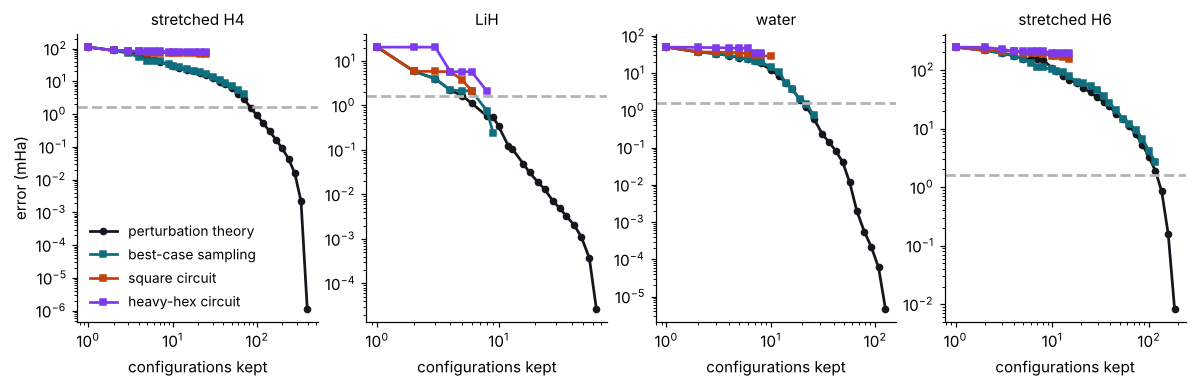

stretched H4, best-case sampling: stalls at k =  71, beats perturbation theory at 5 of 20 sizes
stretched H4,     square circuit: stalls at k =  25, beats perturbation theory at 0 of 14 sizes
stretched H4,  heavy-hex circuit: stalls at k =  25, beats perturbation theory at 0 of 14 sizes
         LiH, best-case sampling: stalls at k =   9, beats perturbation theory at 1 of 8 sizes
         LiH,     square circuit: stalls at k =   6, beats perturbation theory at 0 of 6 sizes
         LiH,  heavy-hex circuit: stalls at k =   8, beats perturbation theory at 0 of 7 sizes
       water, best-case sampling: stalls at k =  26, beats perturbation theory at 1 of 15 sizes
       water,     square circuit: stalls at k =  10, beats perturbation theory at 0 of 9 sizes
       water,  heavy-hex circuit: stalls at k =   8, beats perturbation theory at 0 of 8 sizes
stretched H6, best-case sampling: stalls at k = 117, beats perturbation theory at 5 of 25 sizes
stretched H6,     square circuit: stalls at k

In [8]:
SAMPLERS = [
    ("err_sample", "#0f6e7d", "best-case sampling"),
    ("err_circuit", "#c2410c", "square circuit"),
    ("err_circuit_hh", "#7c3aed", "heavy-hex circuit"),
]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, m in zip(axes, MOLECULES):
    d = res[m]
    sizes = d["sizes"]
    keep = d["err_en"] > 1e-10  # once the error hits zero there is nothing to plot
    ax.loglog(sizes[keep], d["err_en"][keep] * MHA, "o-", c="#14181d", label="perturbation theory")
    for key, c, name in SAMPLERS:
        ok, med = median_reached(d[key])
        ax.loglog(sizes[ok], med * MHA, "s-", c=c, label=name)
    ax.axhline(1.6, c=(.7, .7, .7), ls="--")  # chemical accuracy
    ax.set_title(NAMES[m])
    ax.set_xlabel("configurations kept")
axes[0].set_ylabel("error (mHa)")
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week6/head_to_head_electrons.svg")
plt.show()

for m in MOLECULES:
    d = res[m]
    for key, _, name in SAMPLERS:
        ok, med = median_reached(d[key])
        wins = np.sum(med < d["err_en"][ok])
        print(f"{NAMES[m]:>12}, {name:>18}: stalls at k = {d['sizes'][ok][-1]:3d}, "
              f"beats perturbation theory at {wins} of {ok.sum()} sizes")

Three things to notice, with the numbers in the printout.

First, neither circuit beats perturbation theory at any size on any of the four molecules. The heavy-hex circuit is never better than the square one, and worse at most sizes both reach.

Second, H6 looks like H4, only harder. Both circuits stall at 15 configurations with errors above 150 mHa, while perturbation theory needs 136 configurations to reach the dashed line.

Third, best-case sampling does win a few sizes, mostly on the two stretched chains (5 of 20 sizes on H4 and 5 of 25 on H6). Those are the molecules with the most spread-out answers, which is where sampling should do best. Even there it stalls above the dashed line.

## A noisy preview

Everything so far is noiseless. `make compare-real` also ran the heavy-hex circuit for LiH and water through a simulator that copies the noise of ibm_kingston, one of IBM's Heron chips, for 1,000 shots each. A shot whose electron count comes back wrong is not a row of our matrix, so `configs_from_bitstrings` drops it.

What fraction of LiH's shots come back with the right electron count? Give a decimal, within 0.1.

In [9]:
my_guess = None

In [10]:
FAKE = ["lih", "h2o"]
hw = {m: np.load(f"{ROOT}/results/hardware/{m}.npz") for m in FAKE}
check(my_guess, round(float(res["lih"]["usable_hardware"]), 2), tol=0.1)

for m in FAKE:
    d = res[m]
    found_noisy = configs_from_bitstrings(hw[m]["alpha"], hw[m]["beta"], hams[m]["labels"])[0]
    print(f"{NAMES[m]:>12}: {int(hw[m]['n_two_qubit'])} two-qubit gates, depth {int(hw[m]['depth'])}, "
          f"{float(d['usable_hardware']):.0%} of shots usable")
    print(f"{'':>12}  {len(found_noisy)} configurations from 1,000 noisy shots, "
          f"against {np.median(d['n_found_circuit_hh']):.0f} from 20,000 noiseless ones")

Put your guess in first, then run this cell again
         LiH: 164 two-qubit gates, depth 150, 64% of shots usable
              25 configurations from 1,000 noisy shots, against 8 from 20,000 noiseless ones
       water: 222 two-qubit gates, depth 194, 56% of shots usable
              29 configurations from 1,000 noisy shots, against 10 from 20,000 noiseless ones


Notice how many shots are lost: about a third for LiH, and closer to half for water, whose circuit has more two-qubit gates. The shots that are kept still turn up about three times as many configurations as 20,000 noiseless shots of the same circuit. Noise spreads the samples out. The question is whether it spreads them onto configurations that matter, so we look at which configurations LiH's noisy run returned most often.

most common configurations from the noisy run
up 000011   down 000011   556 times, 0 electrons moved, exact weight 9.7e-01
up 000011   down 100001    13 times, 1 electrons moved, exact weight 1.4e-05
up 100001   down 000011    12 times, 1 electrons moved, exact weight 1.4e-05
up 000011   down 000101    10 times, 1 electrons moved, exact weight 1.5e-03
up 000110   down 000011     6 times, 1 electrons moved, exact weight 7.9e-08
up 000011   down 000110     6 times, 1 electrons moved, exact weight 7.9e-08
up 000101   down 000011     5 times, 1 electrons moved, exact weight 1.5e-03
up 000011   down 010010     4 times, 1 electrons moved, exact weight 1.2e-33


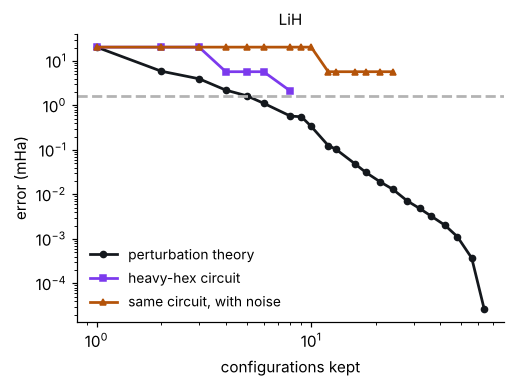

In [11]:
m = "lih"
d, labels = res[m], hams[m]["labels"]
found, counts = configs_from_bitstrings(hw[m]["alpha"], hw[m]["beta"], labels)
hf = labels[0]
print("most common configurations from the noisy run")
for row, n in zip(found[:8], counts[:8]):
    a, b = labels[row]
    moved = (bin(a ^ hf[0]).count("1") + bin(b ^ hf[1]).count("1")) // 2  # electrons moved
    print(f"up {a:06b}   down {b:06b}   {n:3d} times, {moved} electrons moved, "
          f"exact weight {hams[m]['c0'][row] ** 2:.1e}")

fig, ax = plt.subplots(figsize=(5, 3.4))
sizes = d["sizes"]
keep = d["err_en"] > 1e-10
ax.loglog(sizes[keep], d["err_en"][keep] * MHA, "o-", c="#14181d", label="perturbation theory")
ok, med = median_reached(d["err_circuit_hh"])
ax.loglog(sizes[ok], med * MHA, "s-", c="#7c3aed", label="heavy-hex circuit")
ok = ~np.isnan(d["err_hardware"])
ax.loglog(sizes[ok], d["err_hardware"][ok] * MHA, "^-", c="#b45309", label="same circuit, with noise")
ax.axhline(1.6, c=(.7, .7, .7), ls="--")
ax.set_title("LiH")
ax.set_xlabel("configurations kept")
ax.set_ylabel("error (mHa)")
ax.legend()
fig.savefig(f"{ROOT}/figures/week6/noisy_lih.svg")
plt.show()

Notice that every configuration after Hartree-Fock in that list has one electron moved. Moving one electron doesn't lower the Hartree-Fock energy on its own (a result called Brillouin's theorem), so the noisy curve sits at the Hartree-Fock error for the first 10 configurations. The configuration that matters most after Hartree-Fock moves two electrons and has an exact weight of 0.013. It came back twice in 1,000 shots, and the error only drops once it's in, at 12 configurations. So noise adds configurations, but mostly ones that don't help. The real chip's noise will differ in the details, which is what the hardware runs in Tutorial 7 will show.

## Vibrations: the ground state

Now the other half. Water's matrix has 84 configurations (6 quanta) and formic acid's has 715 (4 quanta, for the reason in Tutorial 5). We start with the same ground-state comparison as before, perturbation theory against best-case sampling. There is no vibrational circuit yet, so best case is the only sampler here.

On the Morse model, best-case sampling found 32 to 44 of 512 configurations in 20,000 shots. How many of formic acid's 715 does it find? Within 10.

In [12]:
my_guess = None

Put your guess in first, then run this cell again


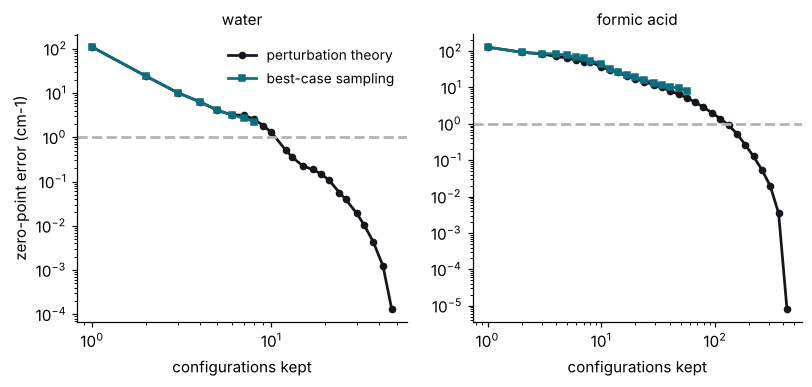

      water: sampling stalls at k = 8 with 2.3 cm-1, beats perturbation theory at 2 of 8 sizes
formic acid: sampling stalls at k = 57 with 8.1 cm-1, beats perturbation theory at 0 of 19 sizes


In [13]:
vres = {v: np.load(f"{ROOT}/results/compare/{v}.npz") for v in VIBRATIONS}
vham = {v: np.load(f"{ROOT}/results/hamiltonians/{v}.npz") for v in VIBRATIONS}
check(my_guess, int(np.median(vres["formic_acid"]["n_found"])), tol=10)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, v in zip(axes, VIBRATIONS):
    d = vres[v]
    sizes = d["sizes"]
    keep = d["err_en"] > 1e-6
    ax.loglog(sizes[keep], d["err_en"][keep], "o-", c="#14181d", label="perturbation theory")
    ok, med = median_reached(d["err_sample"])
    ax.loglog(sizes[ok], med, "s-", c="#0f6e7d", label="best-case sampling")
    ax.axhline(1, c=(.7, .7, .7), ls="--")  # 1 cm-1
    ax.set_title(VNAMES[v])
    ax.set_xlabel("configurations kept")
axes[0].set_ylabel("zero-point error (cm-1)")
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week6/ground_state_vibrations.svg")
plt.show()

for v in VIBRATIONS:
    d = vres[v]
    ok, med = median_reached(d["err_sample"])
    wins = np.sum(med < d["err_en"][ok])
    print(f"{VNAMES[v]:>11}: sampling stalls at k = {d['sizes'][ok][-1]} with {med[-1]:.1f} cm-1, "
          f"beats perturbation theory at {wins} of {ok.sum()} sizes")

Formic acid looks like the molecules, not like the Morse model. Best-case sampling never beats perturbation theory on it. It stalls at 57 configurations with an 8.1 cm-1 error, where perturbation theory is at 5.2, and perturbation theory gets under 1 cm-1 at 132. Water is too small to say much either way: sampling edges ahead at 2 of its 8 sizes and stalls at 8 configurations. So the early lead sampling had on the Morse model doesn't show up on a real 9-mode molecule.

## The fundamentals

An IR spectrum doesn't show the zero-point energy. It shows the fundamentals, the energy to put one quantum into one mode. So we need the excited states too, and sampling the ground state alone is not enough to get them.

Each fundamental's state is mostly the configuration with one quantum in that mode. Formic acid has 9 of those. If we sample its ground state 20,000 times, how many of the 9 come back?

In [14]:
my_guess = None

In [15]:
rows = fundamental_rows(vham["formic_acid"]["labels"])  # all-zero row, then one per mode
found, _ = sample_order(vham["formic_acid"]["c0"], 20000, np.random.default_rng(0))
seen = np.isin(rows[1:], found).sum()
check(my_guess, int(seen))
print(f"{seen} of 9 one-quantum configurations came back from the ground state")

Put your guess in first, then run this cell again
6 of 9 one-quantum configurations came back from the ground state


Six of the nine come back, even though the ground state puts only about 2% of its weight on all nine together. Six is not nine, and a configuration seen a handful of times in 20,000 shots says little about the excited state it belongs to.

So for the fundamentals, both methods target ten states at once: the ground state and the nine fundamentals. Perturbation theory grows one space from the ten seed configurations, scoring each new configuration by its largest contribution to any of the ten states. Sampling splits its shots evenly across the ten exact states, 2,000 each. The plot shows the worst of the fundamental errors at each size.

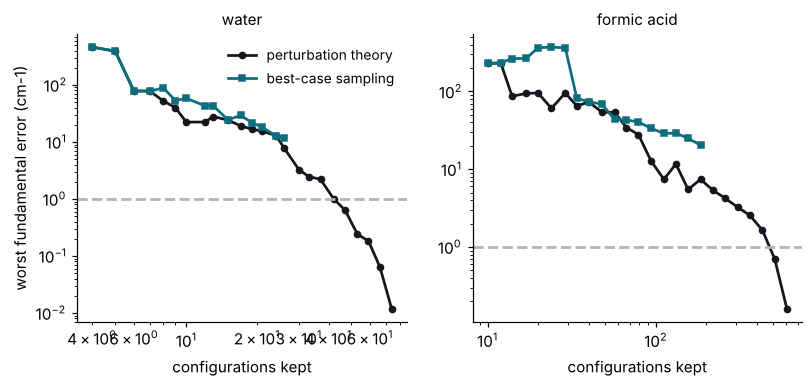

      water: perturbation theory under 1 cm-1 at k = 47; sampling stalls at k = 26 with 11.9 cm-1, beats it at 2 of 15 sizes
formic acid: perturbation theory under 1 cm-1 at k = 510; sampling stalls at k = 185 with 20.4 cm-1, beats it at 1 of 18 sizes


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, v in zip(axes, VIBRATIONS):
    d = vres[v]
    sizes = d["sizes"]
    ok_en = ~np.isnan(d["fund_en"]) & (d["fund_en"] > 1e-6)
    ax.loglog(sizes[ok_en], d["fund_en"][ok_en], "o-", c="#14181d", label="perturbation theory")
    ok, med = median_reached(d["fund_sample"])
    ax.loglog(sizes[ok], med, "s-", c="#0f6e7d", label="best-case sampling")
    ax.axhline(1, c=(.7, .7, .7), ls="--")  # 1 cm-1
    ax.set_title(VNAMES[v])
    ax.set_xlabel("configurations kept")
axes[0].set_ylabel("worst fundamental error (cm-1)")
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week6/fundamentals.svg")
plt.show()

for v in VIBRATIONS:
    d = vres[v]
    k_en = d["sizes"][np.argmax(d["fund_en"] < 1)]
    ok, med = median_reached(d["fund_sample"])
    wins = np.sum(med < d["fund_en"][ok])
    print(f"{VNAMES[v]:>11}: perturbation theory under 1 cm-1 at k = {k_en}; sampling stalls at "
          f"k = {d['sizes'][ok][-1]} with {med[-1]:.1f} cm-1, beats it at {wins} of {ok.sum()} sizes")

Notice that the fundamentals are much harder than the zero-point energy. Perturbation theory first gets every formic acid fundamental within 10 cm-1 at 112 configurations, and within 1 cm-1 only at 510 of the 715. Its curve isn't smooth either. Each energy can only go down as the space grows, but a fundamental is the difference of two energies, so it can move either way.

Sampling the ten exact states stalls at 185 configurations with a worst error of 20 cm-1, and beats perturbation theory at 1 of 18 sizes. On water it stalls at 26 configurations with 12 cm-1, and wins at 2 of 15.

## Does it carry over?

Here is every comparison in one place, as the number of sizes where best-case sampling beat perturbation theory, out of the sizes sampling reached. The two model systems from Tutorial 2 are included for reference.

In [17]:
rows_out = [("chain (model)", np.load(f"{ROOT}/results/compare/hubbard.npz"), "err_sample", "err_en")]
rows_out += [(NAMES[m], res[m], "err_sample", "err_en") for m in MOLECULES]
rows_out += [("Morse (model)", np.load(f"{ROOT}/results/compare/modes.npz"), "err_sample", "err_en")]
rows_out += [(VNAMES[v] + ", zero-point", vres[v], "err_sample", "err_en") for v in VIBRATIONS]
rows_out += [(VNAMES[v] + ", fundamentals", vres[v], "fund_sample", "fund_en") for v in VIBRATIONS]

for name, d, key, ref in rows_out:
    ok, med = median_reached(d[key])
    wins = np.sum(med < d[ref][ok])
    print(f"{name:>26}: sampling wins at {wins:2d} of {ok.sum():2d} sizes")

             chain (model): sampling wins at  0 of 27 sizes
              stretched H4: sampling wins at  5 of 20 sizes
                       LiH: sampling wins at  1 of  8 sizes
                     water: sampling wins at  1 of 15 sizes
              stretched H6: sampling wins at  5 of 25 sizes
             Morse (model): sampling wins at 11 of 15 sizes
         water, zero-point: sampling wins at  2 of  8 sizes
   formic acid, zero-point: sampling wins at  0 of 19 sizes
       water, fundamentals: sampling wins at  2 of 15 sizes
 formic acid, fundamentals: sampling wins at  1 of 18 sizes


The Morse model is the only system where sampling wins most of the time. On every real system, electrons or vibrations, perturbation theory wins at most sizes, and sampling's wins come mostly on the two stretched chains. So far the answer to the project's question is that the ordering carries over: real vibrations behave like the molecules, not like the model. Tutorial 7 looks at why the Morse model was different, and at what the real hardware changes.

## What this does and does not show

Every curve here except the noisy preview is noiseless, and the sampling on the vibrational side is the best case, drawn from the exact states. So this shows how the two ways of choosing compare when sampling is given every advantage, on six real systems. It does not say what IBM's chip will return, how the comparison changes if the circuit's parameters are optimized, or how formic acid's fundamentals compare with the measured spectrum. The noisy preview is a copy of ibm_kingston's noise, not the chip itself. Formic acid is also capped at 4 quanta, so its fundamentals are exact for that matrix but not for the molecule. Tutorial 7 takes these results apart and runs the real hardware.

## Things to try

Each of these is one command from the repo root, then rerun the cells that read its output.

- Give the heavy-hex circuit more layers with `python src/circuits.py -m h4 -p heavy-hex --n-reps 4 --overwrite`, then rerun the energy cell. Does H4 get below Hartree-Fock?
- Give sampling ten times the shots with `python src/compare.py -s formic_acid -n 200000 --overwrite`, then rerun the fundamentals cells. Does it get every fundamental within 1 cm-1, or stall again?
- Grow perturbation theory one configuration at a time with `python src/compare.py -s water -b 1 --overwrite`. Does it reach the fundamentals any sooner?